## Battery storage 

As we have seen before, the absence of energy storage means that we are forced to sell the energy produced by the solar panel to the grid whenever it exceeds the consumption. However, selling electricity is generally less attractive because the export tariff is much lower than the retail electricity price.

A battery can be used to store the excess production, decoupling in time the moment of generation and the moment of consumption. For this reason, battery storage is becoming more and more popular in combination with solar panels. But it can be also employed alone, because it offers a series of advantages: under dynamic electricity tariffs, a battery can be charged during low-price periods and discharged during high-price periods. Also, it offers some backup power in the event of blackouts. Sibelga lists the advantages of battery storage [here](https://www.sibelga.be/en/connections-meters/renewable-energy/home-batteries/why-a-battery).

To perform the calculations, I will employ the same setup as the balcony solar in [chapter](./01_balcony-pv-production.ipynb), while adding a battery pack with a capacity of 1.92 kWh and a peak power output of 1200 W. This setup is sold at a price of around 1230 Eur.

I have considered a very simple case in which the battery is charged when the output of the solar panel is greater than the consumption, and it is discharged when the situation is reversed. This does not take into account any optimization based on forecasts of the energy price or solar production, which is a much harder task but which could potentially optimize the use of the battery.

Using the same balcony PV system analyzed in the previous chapter, adding a 1.92 kWh battery increases annual savings from approximately 122 €/year to 167 €/year. However, because the setup costs an additional 680 Eur, the improvement is relatively modest from a purely economic perspective.


In [1]:
# Compute production
from pathlib import Path
import numpy as np
import pandas as pd
import pvlib
from pvlib.iotools import get_pvgis_hourly
from pvlib.temperature import sapm_cell
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from matplotlib import font_manager as fm
for f in Path("fonts").glob("*.ttf"):   # path relative to the notebook
    fm.fontManager.addfont(str(f))
plt.rcParams["font.family"] = "Montserrat"

lat, lon, alt = 50.817205, 4.377434, 90.452
tilt, azimuth = 90, 223          # vertical, south-facing (pvlib: 180 = south)
tz = "Europe/Brussels"

data, meta = get_pvgis_hourly(
    latitude=lat,
    longitude=lon,
    start=2019,
    end=2023,
    raddatabase="PVGIS-SARAH3",
    components=True,
    surface_tilt=tilt,
    surface_azimuth=azimuth,
    usehorizon=False
)

data.index = data.index.tz_convert("Europe/Brussels")
site = pvlib.location.Location(latitude=lat, longitude=lon, tz=tz, altitude=alt)
solpos = site.get_solarposition(data.index)

hz = pd.read_csv("../data/horizon_balcony.csv")
hz_az, hz_hg = hz["azimuth"].values, hz["horizon_height"].values
sun_horizon = np.interp(solpos["azimuth"], hz_az, hz_hg, period=360)
blocked = (solpos["apparent_elevation"] <= sun_horizon)
data["poa_direct_corr"] = data["poa_direct"].where(~blocked, 0.0)

h = np.radians(hz_hg)
diff = ((hz_az - azimuth + 180) % 360) - 180
front = np.abs(diff) <= 90
weights = np.cos(np.radians(diff[front]))

svf = np.sum(weights * np.cos(h[front])**2) / np.sum(weights)

data['poa_diffuse'] = svf*data['poa_sky_diffuse'] + data['poa_ground_diffuse']
data['poa_global'] = data['poa_direct_corr'] + data['poa_diffuse']

data = data.iloc[:-1]  # drop last row 

temp_cell = sapm_cell(
    poa_global=data["poa_global"],
    temp_air=data["temp_air"],
    wind_speed=data["wind_speed"],
    a=-3.56,
    b=-0.075,
    deltaT=3
)

n_panels = 2
length = 1.96  #m
height = 1.134  #m
area = n_panels * length * height #m2
eta_panel = 0.253
eta_sys = 0.85
P_nom = n_panels * 500 #W
price = 1230  #Eur

bat_capacity = 1.92  # kWh
bat_power = 1200     # W
bat_price = 1230     # Eur

buy_price = 0.30  # Eur/kWh
sell_price = 0.05  # Eur/kWh

gamma = -0.0035  # 1/°C
power = (data["poa_global"]* P_nom/1000 * (1 + gamma*(temp_cell - 25)))

data['P_prod'] = power * eta_sys  #W
data['E_prod'] = data['P_prod']/1000  # kWh

In [2]:
# Compute consumption
rlp = pd.read_excel("../data/RLP0N 2026 Electricity.xlsb", sheet_name="RLP96U", skiprows=5, engine="calamine")
rlp = rlp.set_index("CET")

# Scale to median Brussels annual consumption
E_cons_median = 2000  # kWh/year
rlp["E_cons"] = (E_cons_median * rlp["RLPestU"])

# Convert quarter-hourly to hourly
rlp_hourly = (rlp["E_cons"].resample("h").sum())

rlp_lookup = pd.DataFrame({
    "month": rlp_hourly.index.month,
    "day": rlp_hourly.index.day,
    "hour": rlp_hourly.index.hour,
    "E_cons": rlp_hourly.values
})

data["month"] = data.index.month
data["day"] = data.index.day
data["hour"] = data.index.hour

data_load = data.copy()
data_load["timestamp"] = data.index

data_load = data_load.merge(rlp_lookup, on=["month", "day", "hour"], how="left")
data_load = data_load.set_index("timestamp")
data_load["E_cons"] = data_load["E_cons"].fillna(data_load["E_cons"].shift(24))

Money saved: 835.65 €
Money earned: 0.19 €
Total: 835.84 €
Average yearly total: 167.17 €
Total over 30 years: 5015.06 €


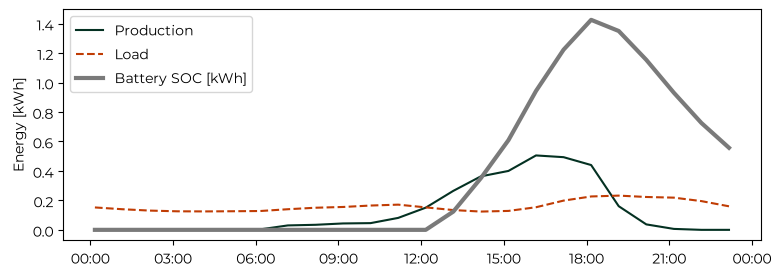

In [7]:

def simulate_battery(prod, load, capacity=bat_capacity, power=bat_power, eta=0.95, soc_min=0.0, dt=1.0):
    """Greedy dispatch: charge from surplus, discharge to cover deficit. prod/load in kWh per step dt [h]."""
    p_max = power / 1000 * dt            # kWh per step
    e_min = soc_min * capacity
    soc = e_min
    n = len(prod)
    soc_hist = np.empty(n)
    grid_import = np.empty(n)
    grid_export = np.empty(n)
    for i in range(n):
        net = prod[i] - load[i]
        if net >= 0:
            charge = min(net, p_max, (capacity - soc) / eta)   # drawn from PV
            soc += charge * eta
            grid_export[i] = net - charge
            grid_import[i] = 0.0
        else:
            need = -net
            discharge = min(need / eta, p_max / eta, soc - e_min)  # taken from battery
            soc -= discharge
            grid_import[i] = need - discharge * eta
            grid_export[i] = 0.0
        soc_hist[i] = soc
    return soc_hist, grid_import, grid_export

soc, imp, exp = simulate_battery(data_load["E_prod"].values, data_load["E_cons"].values)
data_load["soc"] = soc
data_load["E_grid_bat"] = exp - imp
data_load["self_consumed_bat"] = data_load["E_prod"] - np.maximum(data_load["E_grid_bat"], 0)

data_load["money_saved_bat"] = data_load["self_consumed_bat"] * buy_price
data_load["money_earned_bat"] = np.maximum(data_load["E_grid_bat"], 0) * sell_price  

money_saved_bat = data_load["money_saved_bat"].sum()
money_earned_bat = data_load["money_earned_bat"].sum()
money_total_bat = money_saved_bat + money_earned_bat

yearly_total_bat = money_total_bat / 5  # average over 5 years
money_total_30y_bat = yearly_total_bat * 30  # over 30 years

print(f'Money saved: {data_load["money_saved_bat"].sum():.2f} €')
print(f'Money earned: {data_load["money_earned_bat"].sum():.2f} €')
print(f'Total: {data_load["money_saved_bat"].sum() + data_load["money_earned_bat"].sum():.2f} €')

print(f'Average yearly total: {yearly_total_bat:.2f} €')
print(f'Total over 30 years: {money_total_30y_bat:.2f} €')

day = "2023-06-21"
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(data_load.loc[day, "E_prod"], label="Production", color='#043122')
ax.plot(data_load.loc[day, "E_cons"], label="Load", c='#C03C04', ls='--')
ax.plot(data_load.loc[day, "soc"], label="Battery SOC [kWh]", c='#7A7A7A', lw=3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=tz))
ax.set_ylabel("Energy [kWh]")
ax.legend()
plt.show()

The graph shows the production and load relative to the 21th of June 2023, together with the battery state of charge. The battery is charged during the day (12:00-19:00) when the production is greater then the consumption. Then, it is discharged during the evening. Basically, the role of the battery is to spread the production across the day. This is beneficial also from the point of view of the distribution system operator, because a greater share of autoconsumption reduces overloading on the distribution lines. 

Considering again the same 5 years period between 2019 and 2023, the results are the following:
* Money saved: 835.64 Eur,
* Money earned: 0.2 Eur,
* Total 835.84 Eur.

The battery substantially improves the amount of energy that is self-consumed. Basically no energy is sold to the grid, and the total money earned is around 300 Eur higher. However, the price of the setup is also more than double meaning that it would take more time to break even. At a yearly rate of 167.17 Eur, the total of the investment over 30 years would be 5015.02 Eur.

Unlike solar panels, batteries typically experience significant degradation over time. The present calculation assumes no loss of capacity and no replacement costs, and therefore likely overestimates the long-term economic benefit.
